# 05 (PH) - Baseline model: the bar every later model must clear

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Took the three design decisions of this notebook (the feature table as a server table built in SQL, departures as the target, a linear model without station dummies), keeps the horizons, split and metrics of 03 §6.3; runs the notebook and reviews each result |
| Claude Code (AI assistant) | Drafted the feature SQL, the day table, the helpers in `connection.py` and `modelling.py`, the baselines, the ridge model, the checks and the dry run of 6 October (appendix). Logged in `genai-log.md` |

**Goal.** A model is only worth something if it beats a simple rule. The course recipe for time series puts that
first: *naive* and *seasonal naive* baselines before any model, and a linear model as the first trained one. This
notebook lays that bar for the target decided on 6 October (03 §6.1): **departures per station per day**, two
horizons (**the day** and **the rest of the month**), one global model over all stations later. It does three things:

1. **Builds the feature table** that 06 - 10 train on. 04 stopped on purpose at `station_day` (counts per station
   and day) with no features, lags or targets; those are modelling choices and belong here, once, in one place.
2. **Scores the rule baselines** per horizon: no training, just arithmetic on the lags.
3. **Fits one linear model** (ridge regression) on the same features, split and metrics. It is a floor, not a
   candidate: 06 lets PyCaret compare model families; nothing here presumes the winner.

**Products**

| Product | What it is |
| --- | --- |
| `citibike_prep.day_features` | one row per day: calendar, holidays and weather (filled), the same for every station |
| `citibike_prep.station_day_features` | **the feature table**: one row per station and day with the two targets, lags, means, shares, a year earlier, calendar and weather |
| `data/citibike/station_day_features.parquet` | local, git-ignored cache of that table; what 06 - 09 read and what goes to S3 for 10 |
| `citibike/modelling.py` | the split in time, the cold-start rule, the loader and the metrics, imported by every model notebook |
| `models/citibike/05_ridge_*.joblib` | the two ridge models, scored once more on the test period in 09 |
| the score tables of parts 6 - 8 | the bar: MAE, RMSE, WAPE and bias per horizon on validation (2025) and, for the rules, on test (2026) |

**How it is built**
0. Setup.
1. The framing: one row per station and target day, what is known at prediction time, the feature list.
2. Tables.
3. `day_features` in pandas, copied to the server.
4. `station_day_features` in SQL on the server, one year at a time, with checks.
5. Load, split, cold start.
6. The rule baselines, per horizon, on validation and test.
7. A first trained model: ridge regression.
8. Where the errors are, and one chart.
9. Reading and what carries forward.
Appendix: the dry run of 6 October and the failures to expect.

**Status: written for review, nothing below has been executed yet** except the rolled-back dry run of the
appendix. The readings in part 9 are written after the run, from its outputs.

## 0. Setup

Same connection as 02 - 04. The write helpers of 04 (`run()`, `copy_into()`) now live in `connection.py`, next to a
new `copy_out()` that pulls millions of rows through `COPY ... TO STDOUT` (pg8000 parses nothing itself, so it is
many times faster than `pd.read_sql`). `modelling.py` holds what every model notebook must share: the split, the
cold-start rule, the loader and the metrics. 04 keeps its own copies of the write helpers; it has been run and is
left as it was.

In [16]:
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, "..")   # citibike/ -> connection.py and modelling.py
from connection import engine, sql, fmt, check_connection, notebook_style, run, copy_into, PREP_SCHEMA
from modelling import (load_features, scorable, score_table, TARGETS, MIN_HISTORY_DAYS, TRAIN_UNTIL, VALID_UNTIL,
                       MODELS_DIR, FEATURES_PARQUET)

check_connection()
notebook_style()

SCHEMA = PREP_SCHEMA
FIRST_DAY = "2021-01-01"
YEARS = range(2021, 2027)
WEATHER = ["tmax_c", "tmin_c", "prcp_mm", "snow_mm", "snow_depth_mm", "wind_ms"]
print(f"split: train until {TRAIN_UNTIL}, validate until {VALID_UNTIL}, test after; cold start {MIN_HISTORY_DAYS} days")

Connected as r0808910
split: train until 2024-12-31, validate until 2025-12-31, test after; cold start 28 days


## 1. The framing: one row per station and target day

Every row of the feature table is **the forecast for station *s* on day *t*, made on the evening of *t - 1***.
Everything in the row is known by then: the counts up to and including *t - 1*, the calendar of *t*, and the
weather of *t* as NOAA observed it, standing in for the forecast the API will get (03 §6.3, "fair comparison").
The two targets of the 6 October decision are read from that evening:

| Target | Column | Definition | Observed when |
| --- | --- | --- | --- |
| trips **tomorrow** | `y_day` | departures on *t* | always (a quiet day is 0, 04) |
| trips for the **rest of the month** | `y_rest_of_month` | departures from *t* to the last day of *t*'s month | the station's active period covers that month end; otherwise NULL (the station closed, the sum is not a demand) |

So the second horizon is **1 to 31 days long**: the whole month on the 1st, one day on the last day. That is what
an operator asks on any evening ("tomorrow, and until the end of the month"); `days_in_horizon` is a feature, and
the ridge model of part 7 predicts a rate per day and multiplies back. A row is **scorable** when the station has
at least 28 days in its active period (every lag exists; 03 §6.3 "cold start") and the target is observed.

**Lags stay inside the active period.** 04 split a station's life into periods at gaps longer than 60 days. The
window functions partition by station *and* period, so a station reopened in March does not see "last week" in
the previous December: its lags are NULL until it has its own history again. The year-earlier columns are the one
exception: they look up the same station on the same date a year before, whatever the period, and are NULL when
the station was not active then.

**The feature list** (the "why" is 03 §6.3 unless stated)

| Column(s) | What | Why |
| --- | --- | --- |
| `history_days` | days since the period's first day | cold-start rule, and a station's age is a proxy for its maturity |
| `dep_lag_1`, `dep_lag_7`, `dep_lag_14`, `dep_lag_28` | departures 1, 7, 14, 28 days before *t* | yesterday and the same weekday of the last four weeks: the weekly rhythm (02 §3) |
| `dep_mean_7`, `dep_mean_4_weeks` | mean of the last 7 days; mean of the same weekday over 4 weeks | the level, smoothed; `mean_4_weeks` beat `lag_7` at city level (03 §6.2) |
| `dep_mtd` | mean per day so far this month (NULL on the 1st) | the pace of the month, the first rest-of-month baseline |
| `dep_sum_28`, `member_share_28`, `ebike_share_28` | the last 28 days: total, member share, e-bike share | who uses the station; the e-bike shift of H-A, per station |
| `arr_lag_1`, `arr_mean_7` | arrivals yesterday and over the last 7 days | arrivals stay as features (decision 2 of this notebook); the net flow of a station |
| `dep_rest_of_month_ly`, `dep_sum_28_ly` | the same rest-of-month window and the same 28 days, one year earlier | the second rest-of-month baseline: last year's period scaled by the station's growth |
| `days_in_horizon`, `day_of_month`, `month`, `day_of_year`, `iso_dow`, `is_weekend` | the calendar of *t* | week and year season; the length of horizon 2 |
| `holiday`, `day_off`, `holiday_lag_7` | *t* is a holiday (actual date or observed day off); a holiday on a weekday; the reference day of `lag_7` was a holiday | 02 §3.6 and 03 §6.3: a holiday hurts `lag_7` twice, on the day and a week later |
| `tmax_c` ... `wind_ms` | NOAA Central Park on *t*, missing values carried forward | H-D: the weather is where the baseline goes wrong (03 §6.3); **day horizon only** - there is no forecast weeks ahead |

**Not in the table, on purpose**: no station dummies (decision 3: the lags carry each station's level; 06 gives
gradient boosting the station key as a category), no holiday groups by effect size (02 §3.6; an option for 06 if
the holiday error stays large), no city-level lags (an option for 06: yesterday's city total carries a storm).

## 2. Tables

Both `CREATE TABLE IF NOT EXISTS`, as in 04. Counts are `integer`, derived values `real` (a feature needs no
double precision, and the table is 3,9 M rows wide). The primary key (station, day) is also the join key of every
later notebook.

In [3]:
for statement in [
    f"""CREATE TABLE IF NOT EXISTS {SCHEMA}.day_features (
        day date PRIMARY KEY,
        iso_dow smallint NOT NULL, is_weekend boolean NOT NULL,
        month smallint NOT NULL, day_of_month smallint NOT NULL, day_of_year smallint NOT NULL, days_in_horizon smallint NOT NULL,
        holiday boolean NOT NULL, day_off boolean NOT NULL, holiday_lag_7 boolean NOT NULL,
        tmax_c real NOT NULL, tmin_c real NOT NULL, prcp_mm real NOT NULL,
        snow_mm real NOT NULL, snow_depth_mm real NOT NULL, wind_ms real NOT NULL)""",
    f"""CREATE TABLE IF NOT EXISTS {SCHEMA}.station_day_features (
        station_key text NOT NULL, day date NOT NULL, period_no integer NOT NULL, history_days integer NOT NULL,
        y_day integer NOT NULL, y_rest_of_month integer, days_in_horizon smallint NOT NULL,
        dep_lag_1 integer, dep_lag_7 integer, dep_lag_14 integer, dep_lag_28 integer,
        dep_mean_7 real, dep_mean_4_weeks real, dep_mtd real, dep_sum_28 integer,
        member_share_28 real, ebike_share_28 real, arr_lag_1 integer, arr_mean_7 real,
        dep_rest_of_month_ly integer, dep_sum_28_ly integer,
        iso_dow smallint NOT NULL, is_weekend boolean NOT NULL, month smallint NOT NULL, day_of_month smallint NOT NULL,
        day_of_year smallint NOT NULL, holiday boolean NOT NULL, day_off boolean NOT NULL, holiday_lag_7 boolean NOT NULL,
        tmax_c real NOT NULL, tmin_c real NOT NULL, prcp_mm real NOT NULL,
        snow_mm real NOT NULL, snow_depth_mm real NOT NULL, wind_ms real NOT NULL,
        PRIMARY KEY (station_key, day))""",
]:
    run(statement)

- rows in 0,4 s
- rows in 0,4 s


## 3. `day_features`: one row per day

The calendar comes from `citibike.calendar_day` and the weather from `citibike.weather_daily`, read as the login
(the write role has no rights on schema `citibike`, 04 appendix) and copied into `citibike_prep` so that the SQL of
part 4 reads from one schema. From `FIRST_DAY` to the last day of `station_day`, every day present.

- `holiday` = the actual date of a public holiday or the observed day off, as 03 §5 used it; `day_off` = such a
  day on a weekday, the day type that moves demand in 02 §3.6; `holiday_lag_7` = the day a week earlier was a
  holiday (03 §6.3: then `lag_7` is a bad reference).
- The weather has 23 days without wind and 4 without snow depth (02 §3.5). They are filled with the **last
  observed value**: the fill may only look backwards, as any feature must (course recipe, step 3). The first day
  has every value (dry run), so nothing stays empty.
- `days_in_horizon` = days from *t* to the end of its month, inclusive: the length of the second horizon.

In [4]:
last_day = sql(f"SELECT max(day) AS last_day FROM {SCHEMA}.station_day").last_day.iloc[0]
calendar = sql("""
    SELECT day, iso_dow, is_weekend, has_public_holiday, is_observed_day_off
    FROM citibike.calendar_day WHERE day BETWEEN :start AND :end ORDER BY day
""", start=FIRST_DAY, end=last_day)
weather = sql(f"""
    SELECT day, {', '.join(WEATHER)}
    FROM citibike.weather_daily WHERE station = 'USW00094728' AND day BETWEEN :start AND :end ORDER BY day
""", start=FIRST_DAY, end=last_day)
for frame in (calendar, weather):
    frame["day"] = pd.to_datetime(frame.day)
days = calendar.set_index("day").join(weather.set_index("day"), how="left")

assert days.index.equals(pd.date_range(FIRST_DAY, last_day, freq="D")), "calendar_day must cover every day up to the last station day"
missing = days[WEATHER].isna().sum()
print(f"{fmt(len(days))} days, {FIRST_DAY} -> {last_day}; empty weather values: {missing[missing > 0].to_dict()}")
days[WEATHER] = days[WEATHER].ffill()          # last observation carried forward: never a look ahead
assert not days[WEATHER].isna().any().any(), "a weather value is empty on the first day: choose a fill by hand"

days["holiday"] = days.has_public_holiday | days.is_observed_day_off
days["day_off"] = days.holiday & ~days.is_weekend
days["holiday_lag_7"] = days.holiday.shift(7, fill_value=False)      # the first week of 2021 is cold start anyway
days["month"] = days.index.month
days["day_of_month"] = days.index.day
days["day_of_year"] = days.index.dayofyear
days["days_in_horizon"] = (days.index.to_period("M").end_time.normalize() - days.index).days + 1

DAY_COLUMNS = ["day", "iso_dow", "is_weekend", "month", "day_of_month", "day_of_year", "days_in_horizon",
               "holiday", "day_off", "holiday_lag_7"] + WEATHER
day_features = days.reset_index()
day_features["day"] = day_features.day.dt.date
print(f"{fmt(int(days.holiday.sum()))} holiday days, {fmt(int(days.day_off.sum()))} weekday days off "
      f"(03 §5: 88 holiday days up to August 2026)")
copy_into("day_features", day_features, DAY_COLUMNS, delete_where="true")

1 rows in 0,9 s
2.069 rows in 0,6 s
2.069 rows in 0,6 s
2.069 days, 2021-01-01 -> 2026-08-31; empty weather values: {'snow_depth_mm': 4, 'wind_ms': 23}
88 holiday days, 75 weekday days off (03 §5: 88 holiday days up to August 2026)
2.069 rows copied into citibike_prep.day_features (0,2 MB CSV) in 0,7 s


## 4. `station_day_features`: the feature table, in SQL on the server

One `INSERT ... SELECT` per year through `run()`, reading `station_day`, `station_period` and `day_features` only
(plain Postgres, no DuckDB). The window functions do the work:

- window `w` = the station's period, ordered by day: `lag()` for the lags, frames of 7 and 28 preceding rows
  for the means and sums. `station_day` is **dense** inside a period (04 §4.2), so a row offset is a day offset.
- window `m` = the same, partitioned by month: the sum from the current row to the end of the partition is the
  rest-of-month target, the mean before the current row is the month-to-date pace.
- the year earlier is a self-join of the window result on (station, day - 1 year); a leap day lands on 28 February.
- the NULL rules of part 1 are applied in the outer query: a mean over fewer days than its frame promises becomes
  NULL (`history_days` decides), the rest-of-month target is NULL when the period ends before the month end.

**Why one year at a time, and why the window starts on 1 December two years earlier.** The year's rows need 28
days of history before 1 January; their year-earlier rows need the previous year *and its own* 28 days. Starting
the window on 1 December two years back gives both, the year filter in the outer query keeps only the year's
rows. Each statement then handles about 1,5 M rows: 29,6 s for 2025 in the dry run, far below the 10-minute
statement timeout, and progress is visible. `TRUNCATE` first, so a rerun is a full rebuild (about 3 minutes).

In [5]:
FEATURE_COLUMNS = [
    "station_key", "day", "period_no", "history_days",
    "y_day", "y_rest_of_month", "days_in_horizon",
    "dep_lag_1", "dep_lag_7", "dep_lag_14", "dep_lag_28", "dep_mean_7", "dep_mean_4_weeks", "dep_mtd", "dep_sum_28",
    "member_share_28", "ebike_share_28", "arr_lag_1", "arr_mean_7",
    "dep_rest_of_month_ly", "dep_sum_28_ly",
    "iso_dow", "is_weekend", "month", "day_of_month", "day_of_year", "holiday", "day_off", "holiday_lag_7",
] + WEATHER


def station_features_select(year: int) -> str:
    """The SELECT behind the INSERT of one year; its columns are FEATURE_COLUMNS, in that order."""
    return f"""
    WITH w AS (
        SELECT s.station_key, s.day, s.period_no,
               (s.day - p.first_day)                                              AS history_days,
               p.last_day,
               (date_trunc('month', s.day) + interval '1 month - 1 day')::date    AS month_end,
               s.departures                                                       AS y_day,
               sum(s.departures)        OVER (m ROWS BETWEEN CURRENT ROW AND UNBOUNDED FOLLOWING)   AS rest_of_month,
               lag(s.departures, 1)     OVER w                                                      AS dep_lag_1,
               lag(s.departures, 7)     OVER w                                                      AS dep_lag_7,
               lag(s.departures, 14)    OVER w                                                      AS dep_lag_14,
               lag(s.departures, 21)    OVER w                                                      AS dep_lag_21,
               lag(s.departures, 28)    OVER w                                                      AS dep_lag_28,
               avg(s.departures)        OVER (w ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING)           AS dep_mean_7,
               avg(s.departures)        OVER (m ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)   AS dep_mtd,
               sum(s.departures)        OVER (w ROWS BETWEEN 28 PRECEDING AND 1 PRECEDING)          AS dep_sum_28,
               sum(s.departures_member) OVER (w ROWS BETWEEN 28 PRECEDING AND 1 PRECEDING)          AS dep_member_28,
               sum(s.departures_ebike)  OVER (w ROWS BETWEEN 28 PRECEDING AND 1 PRECEDING)          AS dep_ebike_28,
               lag(s.arrivals, 1)       OVER w                                                      AS arr_lag_1,
               avg(s.arrivals)          OVER (w ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING)           AS arr_mean_7
        FROM {SCHEMA}.station_day s
        JOIN {SCHEMA}.station_period p USING (station_key, period_no)
        WHERE s.day >= DATE '{year - 2}-12-01' AND s.day < DATE '{year + 1}-01-01'
        WINDOW w AS (PARTITION BY s.station_key, s.period_no ORDER BY s.day),
               m AS (PARTITION BY s.station_key, s.period_no, date_trunc('month', s.day) ORDER BY s.day)
    )
    SELECT c.station_key, c.day, c.period_no, c.history_days,
           c.y_day,
           CASE WHEN c.last_day >= c.month_end THEN c.rest_of_month END                       AS y_rest_of_month,
           d.days_in_horizon,
           c.dep_lag_1, c.dep_lag_7, c.dep_lag_14, c.dep_lag_28,
           CASE WHEN c.history_days >= 7  THEN c.dep_mean_7 END                               AS dep_mean_7,
           CASE WHEN c.history_days >= 28 THEN (c.dep_lag_7 + c.dep_lag_14 + c.dep_lag_21 + c.dep_lag_28) / 4.0 END AS dep_mean_4_weeks,
           c.dep_mtd,
           CASE WHEN c.history_days >= 28 THEN c.dep_sum_28 END                               AS dep_sum_28,
           CASE WHEN c.history_days >= 28 AND c.dep_sum_28 > 0 THEN c.dep_member_28::float / c.dep_sum_28 END AS member_share_28,
           CASE WHEN c.history_days >= 28 AND c.dep_sum_28 > 0 THEN c.dep_ebike_28::float  / c.dep_sum_28 END AS ebike_share_28,
           c.arr_lag_1,
           CASE WHEN c.history_days >= 7 THEN c.arr_mean_7 END                                AS arr_mean_7,
           CASE WHEN ly.last_day >= ly.month_end THEN ly.rest_of_month END                    AS dep_rest_of_month_ly,
           CASE WHEN ly.history_days >= 28 THEN ly.dep_sum_28 END                             AS dep_sum_28_ly,
           d.iso_dow, d.is_weekend, d.month, d.day_of_month, d.day_of_year, d.holiday, d.day_off, d.holiday_lag_7,
           d.tmax_c, d.tmin_c, d.prcp_mm, d.snow_mm, d.snow_depth_mm, d.wind_ms
    FROM w c
    JOIN {SCHEMA}.day_features d ON d.day = c.day
    LEFT JOIN w ly ON ly.station_key = c.station_key AND ly.day = (c.day - interval '1 year')::date
    WHERE c.day >= DATE '{year}-01-01'
    """


run(f"TRUNCATE {SCHEMA}.station_day_features")
for year in YEARS:
    print(f"station_day_features {year}: ", end="")
    run(f"INSERT INTO {SCHEMA}.station_day_features ({', '.join(FEATURE_COLUMNS)})\n{station_features_select(year)}")

- rows in 0,3 s
station_day_features 2021: 513.920 rows in 18,3 s
station_day_features 2022: 572.627 rows in 31,5 s
station_day_features 2023: 683.874 rows in 38,4 s
station_day_features 2024: 776.861 rows in 44,6 s
station_day_features 2025: 782.694 rows in 45,7 s
station_day_features 2026: 542.845 rows in 37,2 s


### 4.1 Checks

Every station-day of 04 must have exactly one feature row with the same departures; the NULLs must be where the
rules of part 1 put them and nowhere else; and the lags of one station, read back next to `station_day` shifted
by hand, must be the same numbers. The station is the busiest of 2025; it is also the one of the chart in part 8.

In [6]:
shape = sql(f"""
    SELECT (SELECT count(*) FROM {SCHEMA}.station_day_features)                                          AS feature_rows,
           (SELECT count(*) FROM {SCHEMA}.station_day)                                                   AS station_day_rows,
           (SELECT sum(y_day) FROM {SCHEMA}.station_day_features)                                        AS departures,
           (SELECT sum(departures) FROM {SCHEMA}.station_day)                                            AS station_day_departures,
           (SELECT count(*) FROM {SCHEMA}.station_day_features WHERE history_days < {MIN_HISTORY_DAYS})  AS cold_start_rows,
           (SELECT count(*) FROM {SCHEMA}.station_day_features WHERE y_rest_of_month IS NULL)             AS rest_of_month_not_observed,
           (SELECT count(*) FROM {SCHEMA}.station_day_features f JOIN {SCHEMA}.station_period p USING (station_key, period_no)
             WHERE f.y_rest_of_month IS NULL AND p.last_day >= (date_trunc('month', f.day) + interval '1 month - 1 day')::date) AS rest_of_month_wrongly_null,
           (SELECT count(*) FROM {SCHEMA}.station_day_features WHERE dep_lag_28 IS NULL AND history_days >= 28) AS lag_28_wrongly_null,
           (SELECT count(*) FROM {SCHEMA}.station_day_features WHERE dep_rest_of_month_ly IS NULL)        AS without_year_earlier,
           (SELECT count(*) FROM {SCHEMA}.station_day_features WHERE dep_mtd IS NULL)                     AS first_day_of_a_month
""").iloc[0].astype("int64")
display(shape.to_frame("count"))
assert shape.feature_rows == shape.station_day_rows, "every station-day must have exactly one feature row"
assert shape.departures == shape.station_day_departures, "y_day must add up to the departures of station_day"
assert shape.rest_of_month_wrongly_null == 0 and shape.lag_28_wrongly_null == 0

BUSIEST = sql(f"""
    SELECT station_key FROM {SCHEMA}.station_day WHERE day BETWEEN '2025-01-01' AND '2025-12-31'
    GROUP BY station_key ORDER BY sum(departures) DESC LIMIT 1
""").station_key.iloc[0]
check = sql(f"""
    SELECT f.day, f.history_days, f.y_day, f.y_rest_of_month, f.days_in_horizon, f.dep_mtd,
           f.dep_lag_1, s1.departures AS sd_lag_1, f.dep_lag_7, s7.departures AS sd_lag_7, f.dep_lag_28, s28.departures AS sd_lag_28
    FROM {SCHEMA}.station_day_features f
    LEFT JOIN {SCHEMA}.station_day s1  ON s1.station_key  = f.station_key AND s1.day  = f.day - 1  AND s1.period_no  = f.period_no
    LEFT JOIN {SCHEMA}.station_day s7  ON s7.station_key  = f.station_key AND s7.day  = f.day - 7  AND s7.period_no  = f.period_no
    LEFT JOIN {SCHEMA}.station_day s28 ON s28.station_key = f.station_key AND s28.day = f.day - 28 AND s28.period_no = f.period_no
    WHERE f.station_key = :key AND f.day BETWEEN :start AND :end
    ORDER BY f.day
""", key=BUSIEST, start="2024-12-29", end="2025-01-05")
for lag in [1, 7, 28]:
    assert check[f"dep_lag_{lag}"].astype(float).fillna(-1).equals(check[f"sd_lag_{lag}"].astype(float).fillna(-1)), f"lag {lag} differs from station_day"
print(f"station {BUSIEST}: lags 1, 7 and 28 equal station_day shifted by hand; the rest-of-month target restarts on 1 January:")
check

1 rows in 11,5 s


,count
feature_rows,3.872.821
station_day_rows,3.872.821
departures,212.092.181
station_day_departures,212.092.181
cold_start_rows,75.427
rest_of_month_not_observed,6.401
rest_of_month_wrongly_null,0
lag_28_wrongly_null,0
without_year_earlier,869.294
first_day_of_a_month,128.244


1 rows in 1,1 s
8 rows in 0,5 s
station 6140.05: lags 1, 7 and 28 equal station_day shifted by hand; the rest-of-month target restarts on 1 January:


,day,history_days,y_day,y_rest_of_month,days_in_horizon,dep_mtd,dep_lag_1,sd_lag_1,dep_lag_7,sd_lag_7,dep_lag_28,sd_lag_28
0,2024-12-29,1.458,210,767,3,"291,929",89,89,137,137,244,244
1,2024-12-30,1.459,314,557,2,"289,103",210,210,181,181,361,361
2,2024-12-31,1.460,243,243,1,"289,933",314,314,142,142,409,409
3,2025-01-01,1.461,114,8.943,31,,243,243,35,35,403,403
4,2025-01-02,1.462,299,8.829,30,"114,000",114,114,122,122,416,416
5,2025-01-03,1.463,280,8.530,29,"206,500",299,299,186,186,353,353
6,2025-01-04,1.464,226,8.250,28,"231,000",280,280,89,89,330,330
7,2025-01-05,1.465,234,8.024,27,"229,750",226,226,210,210,406,406


## 5. Load, split, cold start

The whole table comes to the laptop once (`copy_out`, then a Parquet cache that 06 - 09 reuse; `refresh=True`
after a rebuild of the table) and gets its `split`: **train 2021 - 2024, validate 2025, test January - August
2026** (03 §6.3). The test rows are touched once in this notebook, by the rules of part 6, which fit nothing;
the ridge model sees them in 09 only.

The table below is what the model notebooks have to work with: rows per split, the cold-start rows that get no
forecast, and the scorable rows per horizon.

In [7]:
df = load_features(refresh=True)
df["station_key"] = df.station_key.astype("category")
print(f"{fmt(len(df))} rows, {fmt(df.station_key.nunique())} stations, {df.day.min():%Y-%m-%d} -> {df.day.max():%Y-%m-%d}, "
      f"{len(df.columns)} columns")

overview = pd.DataFrame({
    "rows": df.groupby("split").size(),
    "stations": df.groupby("split").station_key.nunique(),
    "cold start (no forecast)": df[df.history_days < MIN_HISTORY_DAYS].groupby("split").size(),
    "scorable, day": df[scorable(df, "day")].groupby("split").size(),
    "scorable, rest of month": df[scorable(df, "rest_of_month")].groupby("split").size(),
}).reindex(["train", "valid", "test"]).fillna(0).astype("int64")
display(overview)

print("Departures per station-day (y_day) on the scorable rows: the scale of the errors below")
display(df.loc[scorable(df, "day"), "y_day"].describe(percentiles=[.5, .9, .99]).to_frame().T.round(1))

3.872.821 rows (575 MB CSV) in 50,4 s
cached as data\citibike\station_day_features.parquet (141 MB)
3.872.821 rows, 2.455 stations, 2021-01-01 -> 2026-08-31, 36 columns


,rows,stations,cold start (no forecast),"scorable, day","scorable, rest of month"
split,,,,,
train,2.547.282,2.231,66.857,2.480.425,2.476.569
valid,782.694,2.225,3.543,779.151,778.126
test,542.845,2.373,5.027,537.818,536.450


Departures per station-day (y_day) on the scorable rows: the scale of the errors below


,count,mean,std,min,50%,90%,99%,max
y_day,3.797.394,"55,3","74,1",0,25,152,342,1.380


## 6. The rule baselines

No training, no parameters: each rule is one column of the table, or two columns and a multiplication. Scored on
**validation** (2025) and on **test** (2026) at once, because nothing is fitted. Metrics per station-day
(03 §6.3): **MAE** and **RMSE** in departures, **WAPE** (sum of absolute errors over sum of actuals, in %) because
stations differ by an order of magnitude in volume, and the **bias** (mean of predicted minus actual: negative =
the rule predicts too few).

| Horizon | Rule | What it does |
| --- | --- | --- |
| day | naive | yesterday (`dep_lag_1`); the course's "tomorrow = today" |
| day | seasonal naive | the same weekday last week (`dep_lag_7`); the baseline of the 6 October decision |
| day | mean of 4 weeks | the same weekday over the last four weeks (`dep_mean_4_weeks`); the better rule at city level in 03 §6.2 |
| rest of month | pace, month to date | the mean per day so far this month times the days left; on the 1st, last week's mean |
| rest of month | pace, last 7 days | last week's mean per day times the days left |
| rest of month | last year scaled | the same rest-of-month window a year earlier, times the station's growth (last 28 days over the same 28 days a year earlier); where the station has no usable year earlier, last week's pace |

Every rule is defined on every scorable row (the fallbacks make sure of that), so the methods are compared on
exactly the same rows. The number of fallback rows is printed.

In [8]:
def baseline_predictions(d: pd.DataFrame, horizon: str) -> dict[str, pd.Series]:
    if horizon == "day":
        return {"naive (yesterday)": d.dep_lag_1,
                "seasonal naive (same weekday last week)": d.dep_lag_7,
                "mean of the same weekday, 4 weeks": d.dep_mean_4_weeks}
    pace_week = d.dep_mean_7 * d.days_in_horizon
    pace_mtd = d.dep_mtd.fillna(d.dep_mean_7) * d.days_in_horizon
    growth = d.dep_sum_28 / d.dep_sum_28_ly
    last_year = (d.dep_rest_of_month_ly * growth).where(lambda s: np.isfinite(s))
    print(f"last year scaled: {fmt(int(last_year.isna().sum()))} of {fmt(len(d))} rows without a usable year earlier "
          f"({last_year.isna().mean() * 100:.1f} %), filled with last week's pace")
    return {"pace, month to date x days left": pace_mtd,
            "pace, last 7 days x days left": pace_week,
            "last year, same period x growth": last_year.fillna(pace_week)}


baseline_scores = {}
for horizon, target in TARGETS.items():
    parts = {}
    for split in ["valid", "test"]:
        d = df[(df.split == split) & scorable(df, horizon)]
        parts[split] = score_table(d, baseline_predictions(d, horizon), target)
    baseline_scores[horizon] = pd.concat(parts, names=["split"])
    print(f"\nHorizon {horizon}: validation 2025 and test January - August 2026, departures per station-day")
    display(baseline_scores[horizon].round(2))


Horizon day: validation 2025 and test January - August 2026, departures per station-day


MAE   RMSE  WAPE_%  bias  \
split method                                                                
valid naive (yesterday)                        14.87  29.54   25.38  0.04   
      seasonal naive (same weekday last week)  16.08  32.34   27.46  0.16   
      mean of the same weekday, 4 weeks        14.57  29.14   24.87  0.17   
test  naive (yesterday)                        15.43  30.98   27.66 -0.20   
      seasonal naive (same weekday last week)  17.77  35.81   31.87 -1.71   
      mean of the same weekday, 4 weeks        15.57  30.72   27.92 -3.63   

                                                    n  
split method                                           
valid naive (yesterday)                        779151  
      seasonal naive (same weekday last week)  779151  
      mean of the same weekday, 4 weeks        779151  
test  naive (yesterday)                        537818  
      seasonal naive (same weekday last week)  537818  
      mean of the same weekday, 4 weeks        537818

last year scaled: 24.142 of 778.126 rows without a usable year earlier (3.1 %), filled with last week's pace
last year scaled: 29.438 of 536.450 rows without a usable year earlier (5.5 %), filled with last week's pace

Horizon rest_of_month: validation 2025 and test January - August 2026, departures per station-day


MAE     RMSE  WAPE_%   bias       n
split method                                                                 
valid pace, month to date x days left  169.92   398.23   18.55  21.25  778126
      pace, last 7 days x days left    149.06   343.09   16.28  13.40  778126
      last year, same period x growth  147.61  1504.86   16.12  36.48  778126
test  pace, month to date x days left  161.58   378.46   18.21 -54.23  536450
      pace, last 7 days x days left    154.55   352.99   17.42 -39.19  536450
      last year, same period x growth  167.56  2953.85   18.88  14.69  536450

### 6.1 By station size

A quiet station and a busy one are not the same problem: the first has errors of a few departures that are large in
percent, the second has errors of tens of departures that dominate the MAE. Quartiles of the station's recent
volume (`dep_mean_4_weeks`) on the validation rows, horizon day.

In [9]:
d = df[(df.split == "valid") & scorable(df, "day")].copy()
d["station size"] = pd.qcut(d.dep_mean_4_weeks, 4, labels=["Q1 quiet", "Q2", "Q3", "Q4 busy"], duplicates="drop")
print("Validation 2025, horizon day, per quartile of the station's mean of the same weekday over 4 weeks:")
display(d.groupby("station size", observed=True).dep_mean_4_weeks.agg(["min", "max"]).round(1).T)
display(score_table(d, baseline_predictions(d, "day"), "y_day", by="station size").round(2))

Validation 2025, horizon day, per quartile of the station's mean of the same weekday over 4 weeks:


station size,Q1 quiet,Q2,Q3,Q4 busy
min,"0,0","9,8","26,5","79,0"
max,"9,5","26,2","78,8","1.079,2"


,,MAE,RMSE,WAPE_%,bias,n
station size,method,,,,,
Q1 quiet,naive (yesterday),"3,01","4,54","51,70","0,18",198.006
Q2,naive (yesterday),"5,99","8,34","35,46","0,21",192.534
Q3,naive (yesterday),"13,42","19,71","27,66","0,80",194.034
Q4 busy,naive (yesterday),"37,15","54,94","22,72","-1,05",194.577
Q1 quiet,seasonal naive (same weekday last week),"3,14","5,75","53,94","-0,56",198.006
Q2,seasonal naive (same weekday last week),"6,36","8,62","37,67","-0,20",192.534
Q3,seasonal naive (same weekday last week),"14,83","21,02","30,57","-0,79",194.034
Q4 busy,seasonal naive (same weekday last week),"40,12","60,34","24,54","2,18",194.577
Q1 quiet,"mean of the same weekday, 4 weeks","2,73","5,42","46,87","-0,58",198.006


## 7. A first trained model: ridge regression

The course names the linear model as the baseline every complex model must beat, and it is the honest first
step here: it can only combine the lags, the calendar and the weather **linearly**, so whatever a tree model gains
in 06 is a measured gain over that. **Ridge** is linear regression with an L2 penalty: the lags are strongly
correlated with each other (the same weekday over four weeks), and without the penalty their coefficients would
take large opposite values that change with every split (the variance of the 2 October lesson). Alpha stays at
its default: tuning is 08's job, and tuning the floor would only lift it.

- **Inputs**, standardised: the history columns, the holiday flags, and for the **day** horizon the six weather
  values of the day; the weekday and the month are one-hot (a weekday is a category, not a number).
- **No station dummies** (decision 3). The lags already carry each station's level, so the model knows how busy a
  station is without knowing which station it is; 2.455 dummies would make the floor wide, slow and no better.
  06 gives gradient boosting the station key as a category and measures what it adds.
- **Rest of month as a rate.** The target spans 1 to 31 days, so the model predicts **departures per remaining
  day** and multiplies by `days_in_horizon`: one scale for the coefficients, the transformation undone before the
  error is measured (course recipe, step 8). Its rate inputs: the month-to-date pace and the scaled year-earlier
  rate, with last week's mean as fallback and a flag that says when the fallback was used.
- Negative predictions are clipped to 0: a count cannot be negative.
- Fitted on **train**, scored on **validation** next to the rules of part 6. Not on test: that is 09's one look.

What this model is not: a candidate. 06 lets PyCaret compare model families on the same table and split; the
choice of model is made there, by numbers.

In [10]:
CALENDAR = ["iso_dow", "month"]
FLAGS = ["holiday", "day_off", "holiday_lag_7"]
HISTORY = ["dep_lag_1", "dep_lag_7", "dep_lag_14", "dep_lag_28", "dep_mean_7", "dep_mean_4_weeks",
           "arr_lag_1", "arr_mean_7", "member_share_28", "ebike_share_28", "history_days"]
RATES = ["days_in_horizon", "day_of_month", "mtd_rate", "last_year_rate", "has_last_year"]
FEATURES_DAY = HISTORY + FLAGS + WEATHER + CALENDAR
FEATURES_REST = HISTORY + FLAGS + RATES + CALENDAR


def design(d: pd.DataFrame) -> pd.DataFrame:
    """The model inputs for the rows of d: flags as 0/1, shares of a station without departures as 0,
    the rest-of-month rates with their fallbacks and the fallback flag."""
    x = d[HISTORY + FLAGS + WEATHER + CALENDAR + ["days_in_horizon", "day_of_month"]].copy()
    x[FLAGS] = x[FLAGS].astype(int)
    x[["member_share_28", "ebike_share_28"]] = x[["member_share_28", "ebike_share_28"]].fillna(0)
    x["mtd_rate"] = d.dep_mtd.fillna(d.dep_mean_7)
    last_year_rate = (d.dep_rest_of_month_ly * (d.dep_sum_28 / d.dep_sum_28_ly) / d.days_in_horizon).where(lambda s: np.isfinite(s))
    x["has_last_year"] = last_year_rate.notna().astype(int)
    x["last_year_rate"] = last_year_rate.fillna(d.dep_mean_7)
    assert not x.isna().any().any(), x.isna().sum()[lambda s: s > 0]
    return x


def ridge_pipeline(features: list[str]) -> Pipeline:
    numeric = [f for f in features if f not in CALENDAR]
    return Pipeline([
        ("inputs", ColumnTransformer([("calendar", OneHotEncoder(handle_unknown="ignore"), CALENDAR),
                                      ("numeric", StandardScaler(), numeric)], sparse_threshold=0)),
        ("ridge", Ridge(alpha=1.0)),
    ])


train = df[(df.split == "train") & scorable(df, "day")]
valid = df[(df.split == "valid") & scorable(df, "day")]
t0 = time.time()
ridge_day = ridge_pipeline(FEATURES_DAY).fit(design(train)[FEATURES_DAY], train.y_day)
print(f"ridge, horizon day: fitted on {fmt(len(train))} rows, {len(FEATURES_DAY)} inputs, in {fmt(time.time() - t0, '.0f')} s")
pred_day = pd.Series(ridge_day.predict(design(valid)[FEATURES_DAY]), index=valid.index).clip(lower=0)

print("Validation 2025, horizon day: the rules and the ridge model on the same rows")
compare_day = score_table(valid, {**baseline_predictions(valid, "day"), "ridge (lags, calendar, weather)": pred_day}, "y_day")
display(compare_day.round(2))

ridge, horizon day: fitted on 2.480.425 rows, 22 inputs, in 14 s
Validation 2025, horizon day: the rules and the ridge model on the same rows


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
naive (yesterday),"14,87","29,54","25,38","0,04",779.151
seasonal naive (same weekday last week),"16,08","32,34","27,46","0,16",779.151
"mean of the same weekday, 4 weeks","14,57","29,14","24,87","0,17",779.151
"ridge (lags, calendar, weather)","11,92","22,67","20,34","-0,34",779.151


In [11]:
train_rest = df[(df.split == "train") & scorable(df, "rest_of_month")]
valid_rest = df[(df.split == "valid") & scorable(df, "rest_of_month")]
t0 = time.time()
ridge_rest = ridge_pipeline(FEATURES_REST).fit(design(train_rest)[FEATURES_REST], train_rest.y_rest_of_month / train_rest.days_in_horizon)
print(f"ridge, horizon rest of month (rate per day): fitted on {fmt(len(train_rest))} rows, {len(FEATURES_REST)} inputs, "
      f"in {fmt(time.time() - t0, '.0f')} s")
pred_rest = (pd.Series(ridge_rest.predict(design(valid_rest)[FEATURES_REST]), index=valid_rest.index) * valid_rest.days_in_horizon).clip(lower=0)

print("Validation 2025, horizon rest of month: the rules and the ridge model on the same rows")
compare_rest = score_table(valid_rest, {**baseline_predictions(valid_rest, "rest_of_month"), "ridge (rate x days left)": pred_rest}, "y_rest_of_month")
display(compare_rest.round(2))

print("The same, per length of the horizon (days left in the month): a 1-day horizon is a different problem from a 31-day one")
by_length = valid_rest.assign(**{"days left": pd.cut(valid_rest.days_in_horizon, [0, 7, 14, 21, 31], labels=["1 - 7", "8 - 14", "15 - 21", "22 - 31"])})
display(score_table(by_length, {"pace, last 7 days x days left": baseline_predictions(valid_rest, "rest_of_month")["pace, last 7 days x days left"],
                                "ridge (rate x days left)": pred_rest}, "y_rest_of_month", by="days left").round(2))

ridge, horizon rest of month (rate per day): fitted on 2.476.569 rows, 21 inputs, in 8 s
Validation 2025, horizon rest of month: the rules and the ridge model on the same rows
last year scaled: 24.142 of 778.126 rows without a usable year earlier (3.1 %), filled with last week's pace


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
"pace, month to date x days left","169,92","398,23","18,55","21,25",778.126
"pace, last 7 days x days left","149,06","343,09","16,28","13,40",778.126
"last year, same period x growth","147,61","1.504,86","16,12","36,48",778.126
ridge (rate x days left),"150,20","314,26","16,40","1,25",778.126


The same, per length of the horizon (days left in the month): a 1-day horizon is a different problem from a 31-day one
last year scaled: 24.142 of 778.126 rows without a usable year earlier (3.1 %), filled with last week's pace


,,MAE,RMSE,WAPE_%,bias,n
days left,method,,,,,
1 - 7,"pace, last 7 days x days left","45,08","97,11","19,40","-2,86",179.452
8 - 14,"pace, last 7 days x days left","103,76","210,39","16,33","6,40",179.233
15 - 21,"pace, last 7 days x days left","165,26","347,56","15,82","8,32",178.979
22 - 31,"pace, last 7 days x days left","248,37","500,96","16,14","34,52",240.462
1 - 7,ridge (rate x days left),"44,07","90,49","18,96","-11,30",179.452
8 - 14,ridge (rate x days left),"102,38","194,91","16,11","-10,99",179.233
15 - 21,ridge (rate x days left),"160,67","309,98","15,38","-11,40",178.979
22 - 31,ridge (rate x days left),"257,26","462,22","16,71","29,15",240.462


### 7.1 Save the models, and what the day model leans on

The two pipelines go to `models/citibike/` (git-ignored, like every `.pkl`): 09 loads them and scores them on the
test period once, next to the models of 06 - 08 and 10. The coefficients are on **standardised** inputs, so they
are comparable: departures per standard deviation of the input (one-hot columns are 0/1). They are a reading aid,
not a feature selection.

In [12]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
for name, model in [("05_ridge_day", ridge_day), ("05_ridge_rest_of_month", ridge_rest)]:
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")
print(f"saved {', '.join(p.name for p in sorted(MODELS_DIR.glob('05_ridge_*.joblib')))} in {MODELS_DIR}")

coef = pd.Series(ridge_day["ridge"].coef_, index=ridge_day["inputs"].get_feature_names_out()).sort_values(key=abs, ascending=False)
print("Horizon day: the 12 largest coefficients")
coef.head(12).round(2).to_frame("coefficient")

saved 05_ridge_day.joblib, 05_ridge_rest_of_month.joblib in C:\localdata\repo\cloud-ai-avenue-5\models\citibike
Horizon day: the 12 largest coefficients


,coefficient
numeric__dep_mean_4_weeks,"26,08"
numeric__dep_mean_7,"18,12"
numeric__arr_lag_1,"13,70"
numeric__dep_lag_1,"13,24"
numeric__tmax_c,"9,81"
calendar__month_1,"7,85"
calendar__month_2,"6,47"
calendar__month_7,"-6,30"
calendar__month_8,"-6,00"
calendar__month_3,"5,31"


## 8. Where the errors are

Three cuts of the validation errors, horizon day, for the seasonal naive rule and the ridge model:

- **holidays**: 03 §6.3 showed `lag_7` predicts too many trips on a holiday and too few a week later; the
  holiday flags should let the ridge model close part of that;
- **rain**: H-D, the larger lever; a wet day is more than 2 mm as in 03 §5;
- **the city total**: the station forecasts summed per day, on the **test** period, next to the city-level
  baseline of 03 §6.2 (`lag_7` MAE 29.799, `mean_4_weeks` 27.123 trips per day). Not the same number: the station
  sum has no trips without a start station, no other-region ids and no cold-start stations, and it includes
  23 February 2026 (0 departures), which 03 dropped. Close is the point; identical is not expected.

In [13]:
cuts = valid.assign(**{
    "day group": np.select([valid.holiday, valid.holiday_lag_7], ["holiday", "a week after a holiday"], "other day"),
    "rain": np.where(valid.prcp_mm > 2, "wet (> 2 mm)", "dry"),
})
preds = {"seasonal naive": valid.dep_lag_7, "ridge": pred_day}
print("Validation 2025, horizon day: holidays")
display(score_table(cuts, preds, "y_day", by="day group").round(2))
print("Validation 2025, horizon day: rain")
display(score_table(cuts, preds, "y_day", by="rain").round(2))

Validation 2025, horizon day: holidays


,,MAE,RMSE,WAPE_%,bias,n
day group,method,,,,,
a week after a holiday,seasonal naive,"19,80","38,08","36,45","-15,35",25.600
holiday,seasonal naive,"24,17","46,91","61,50","17,62",29.886
other day,seasonal naive,"15,62","31,37","26,24","-0,02",723.665
a week after a holiday,ridge,"10,37","19,88","19,10","-3,14",25.600
holiday,ridge,"14,29","27,52","36,37","4,91",29.886
other day,ridge,"11,87","22,54","19,95","-0,46",723.665


Validation 2025, horizon day: rain


,,MAE,RMSE,WAPE_%,bias,n
rain,method,,,,,
dry,seasonal naive,"15,00","30,29","24,37","-2,73",610.433
wet (> 2 mm),seasonal naive,"20,00","38,87","41,84","10,60",168.718
dry,ridge,"11,29","21,26","18,35","-2,11",610.433
wet (> 2 mm),ridge,"14,17","27,16","29,63","6,07",168.718


In [14]:
test = df[(df.split == "test") & scorable(df, "day")]
city = pd.DataFrame({"actual": test.groupby("day").y_day.sum(),
                     "seasonal naive": test.groupby("day").dep_lag_7.sum(),
                     "mean of 4 weeks": test.groupby("day").dep_mean_4_weeks.sum()})
print(f"Test period, {fmt(len(city))} days, mean {fmt(city.actual.mean(), ',.0f')} departures per day over the scorable stations "
      f"(03 §6.3: 124.859 trips per day); the station rules summed per day, next to 03's 29.799 (lag_7) and 27.123 (mean_4_weeks):")
score_table(city, {"seasonal naive, summed": city["seasonal naive"], "mean of 4 weeks, summed": city["mean of 4 weeks"]}, "actual").round(1)

Test period, 243 days, mean 123.412 departures per day over the scorable stations (03 §6.3: 124.859 trips per day); the station rules summed per day, next to 03's 29.799 (lag_7) and 27.123 (mean_4_weeks):


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
"seasonal naive, summed",29.834,"39.826,5","24,2","-3.793,5",243
"mean of 4 weeks, summed",26.937,"34.088,3","21,8","-8.028,8",243


### 8.1 One station, eight weeks

The busiest station of 2025 over eight validation weeks (5 May - 29 June 2025): the actual departures, the seasonal
naive rule and the ridge model. A picture of what the numbers above mean, not evidence on its own.

1 rows in 0,3 s


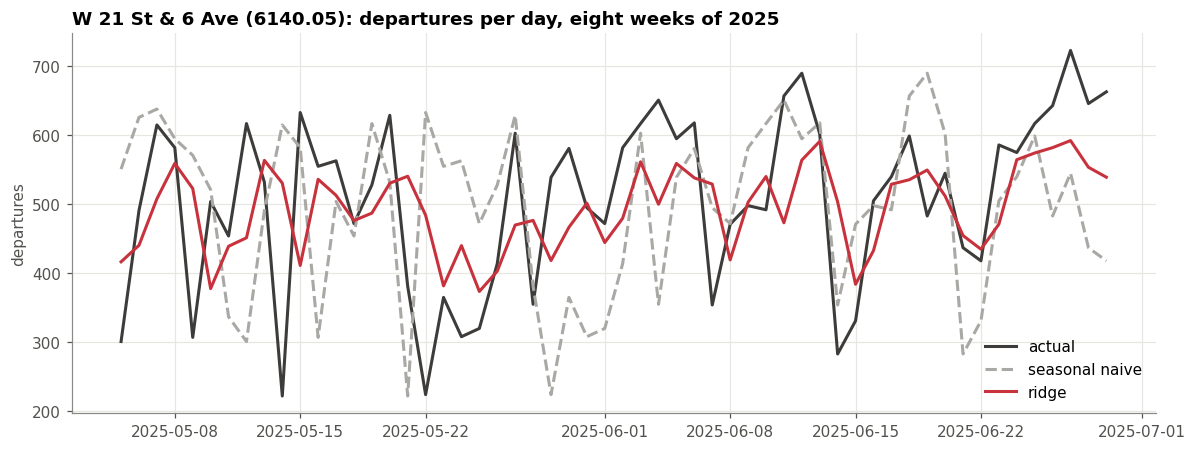

MAE over these 56 days: seasonal naive 127,2, ridge 87,6


In [17]:
name = sql(f"SELECT name FROM {SCHEMA}.station_dim WHERE station_key = :key", key=BUSIEST).name.iloc[0]
window = valid[(valid.station_key == BUSIEST) & (valid.day >= "2025-05-05") & (valid.day < "2025-06-30")].sort_values("day")

fig, ax = plt.subplots()
ax.plot(window.day, window.y_day, color="#3d3c3a", label="actual")
ax.plot(window.day, window.dep_lag_7, color="#a9a8a4", linestyle="--", label="seasonal naive")
ax.plot(window.day, pred_day.loc[window.index], color="#c8323c", label="ridge")
ax.set_title(f"{name} ({BUSIEST}): departures per day, eight weeks of 2025")
ax.set_ylabel("departures")
ax.legend()
plt.tight_layout()
plt.show()
print(f"MAE over these {len(window)} days: seasonal naive {fmt((window.dep_lag_7 - window.y_day).abs().mean(), '.1f')}, "
      f"ridge {fmt((pred_day.loc[window.index] - window.y_day).abs().mean(), '.1f')}")

## 9. Reading and what carries forward

Run of 7 October 2026 (team lead). Scorable rows for the day horizon: 2.480.425 train, 779.151 validation,
537.818 test; the cold-start rule withholds 75.427 station-days (1,9 %).

| Horizon | Best rule (validation MAE) | Ridge (validation MAE) | Test, best rule |
| --- | --- | --- | --- |
| day | mean of the same weekday, 4 weeks: **14,57** (WAPE 24,9 %) | **11,92** (WAPE 20,3 %), 18 % better | yesterday 15,43 |
| rest of month | last 7 days x days left: **149,1** (WAPE 16,3 %) | 150,2: no gain, better RMSE (314 vs 343) and no bias | 154,6 |

- **Day.** The ridge gains on holidays (seasonal naive MAE 24,2 on a holiday and 19,8 a week after, ridge 14,3 and
  10,4: the flags work) and on wet days (20,0 -> 14,2). Wet days stay 25 % worse than dry ones with a bias of +6:
  one linear coefficient for rain cannot tell drizzle from a storm. Lead for 06.
- **Rest of month.** The ridge is better up to 21 days left and worse beyond (257 vs 248): a linear rate over-predicts
  whole months. The year-earlier rule has the same MAE as the weekly pace but an RMSE of 1.505: the growth factor
  explodes where a station was almost empty a year earlier; cap it before 09 uses it. This horizon is where 06 must
  prove itself, with the month season and the year earlier as inputs.
- **Station size.** The MAE sits in the busy quarter (MAE 37), the percentage error in the quiet one (WAPE 47 - 54 %);
  hence WAPE next to MAE in 09, and a count objective as an option for 06.
- **City check.** Station rules summed per day on the test period: 29.834 and 26.937 against 29.799 and 27.123 in
  03 §6.3. The feature table reproduces the city baseline to within 0,7 %.

**What 06 - 10 take from here:** the feature table and its Parquet cache (a new feature is added here, once);
`modelling.py` for split and scoring; the bar above; the two ridge models saved for 09's one look at the test period.

## Appendix: the dry run of 6 October, and the failures to expect

Run from the laptop as the notebook login, everything in **one transaction that was rolled back**: `day_features`
in a temporary table, the feature SELECT of part 4 for 2024 and 2025 on three stations (the busiest of 2025, one
reopened in 2025, one opened in March 2025), and the 2025 SELECT for all stations counted on the server.

| Check | Result |
| --- | --- |
| `day_features` | 2.069 days, 2021-01-01 -> 2026-08-31, no gap in calendar or weather; 88 holiday days, 75 weekday days off; 4 snow depths and 23 wind values filled forward (first empty value 2021-09-09, so the first day is complete) |
| lags | `dep_lag_1`, `_7`, `_14`, `_28` equal `station_day` shifted by hand, inside the same period, on 400 sampled rows |
| rest of month | `y_rest_of_month` equals the sum from the day to the month end on the same rows; `days_in_horizon` = month end - day + 1 |
| year earlier | `dep_rest_of_month_ly` and `dep_sum_28_ly` equal the 2024 rows' `y_rest_of_month` and `dep_sum_28` on 200 sampled rows |
| NULL pattern | the station opened in March has no year earlier at all; the reopened one has none for the months before its first period; `dep_mtd` is NULL on the first day of each month and the first day of a period |
| 2025, all stations | 782.694 rows = the station-day rows of 2025, 45.736.108 departures, 781.648 with an observed rest-of-month target, 779.151 with `dep_lag_28`, 760.822 with a year earlier; **29,6 s** on the server |

| Symptom | Cause | Fix |
| --- | --- | --- |
| `cannot execute ... in a read-only transaction` | the logins start read-only (04 appendix) | built into `run()` and `copy_into()`; nothing to do |
| `permission denied for schema citibike` in part 4 | the write role cannot read `calendar_day` or `weather_daily` | by design part 3 copies them into `day_features` as the login; part 4 reads `citibike_prep` only |
| `duplicate key value violates unique constraint` | part 4 run twice without the `TRUNCATE`, or `day_features` copied without `delete_where` | run the cell from its first line |
| statement timeout (10 min) in part 4 | a year took far longer than the 29,6 s measured | run that year alone; if it persists, split the year in two with a `month_end` filter |
| `copy_out` slow or the kernel short of memory in part 5 | the whole table comes over the VPN as CSV, about 3,9 M rows (expected: a few hundred MB, a few minutes; not measured) | run once; afterwards `load_features()` reads the Parquet cache |

In [ ]:
engine.dispose()